## import libraries and functions and row

In [1]:
%load_ext autoreload
%autoreload 2
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
sys.path.append("..")
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.2f}".format)

from src.extraction import load_row, save_processed

df = load_row()

df

,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.50,55.00,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.80,61.00,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.90,65.00,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.40,58.00,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.30,58.00,335,4.34,4.35,2.75
...,...,...,...,...,...,...,...,...,...,...
49995,0.72,Ideal,D,SI1,60.80,57.00,2757,5.75,5.76,3.50
49996,0.72,Good,D,SI1,63.10,55.00,2757,5.69,5.75,3.61
49997,0.70,Very Good,D,SI1,62.80,60.00,2757,5.66,5.68,3.56
49998,0.86,Premium,H,SI2,61.00,58.00,2757,6.15,6.12,3.74


## data description

In [2]:
display(df.head())
print(df.shape)
display(df.info)
display(df.describe())
print(df.dtypes)

,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.50,55.00,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.80,61.00,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.90,65.00,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.40,58.00,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.30,58.00,335,4.34,4.35,2.75


(50000, 10)


<bound method DataFrame.info of        carat        cut color clarity  depth  table  price    x    y    z
0       0.23      Ideal     E     SI2  61.50  55.00    326 3.95 3.98 2.43
1       0.21    Premium     E     SI1  59.80  61.00    326 3.89 3.84 2.31
2       0.23       Good     E     VS1  56.90  65.00    327 4.05 4.07 2.31
3       0.29    Premium     I     VS2  62.40  58.00    334 4.20 4.23 2.63
4       0.31       Good     J     SI2  63.30  58.00    335 4.34 4.35 2.75
...      ...        ...   ...     ...    ...    ...    ...  ...  ...  ...
49995   0.72      Ideal     D     SI1  60.80  57.00   2757 5.75 5.76 3.50
49996   0.72       Good     D     SI1  63.10  55.00   2757 5.69 5.75 3.61
49997   0.70  Very Good     D     SI1  62.80  60.00   2757 5.66 5.68 3.56
49998   0.86    Premium     H     SI2  61.00  58.00   2757 6.15 6.12 3.74
49999   0.75      Ideal     D     SI2  62.20  55.00   2757 5.83 5.87 3.64

[50000 rows x 10 columns]>

,carat,depth,table,price,x,y,z
count,50000.00,50000.00,50000.00,50000.00,50000.00,50000.00,50000.00
mean,0.80,61.75,57.46,3944.81,5.73,5.74,3.54
std,0.48,1.43,2.23,3997.94,1.12,1.15,0.71
min,0.20,43.00,43.00,326.00,0.00,0.00,0.00
25%,0.40,61.00,56.00,951.00,4.71,4.72,2.91
50%,0.70,61.80,57.00,2410.00,5.70,5.71,3.53
75%,1.04,62.50,59.00,5351.00,6.54,6.54,4.04
max,5.01,79.00,95.00,18823.00,10.74,58.90,31.80


carat      float64
cut            str
color          str
clarity        str
depth      float64
table      float64
price        int64
x          float64
y          float64
z          float64
dtype: object


## Numerical and Categories variables 

In [3]:
numerical_df = df.select_dtypes(include=['number'])

categorical_df = df.select_dtypes(include=['category', 'object'])

display(numerical_df.head())
display(categorical_df.head())

C:\Users\lenovo pc\AppData\Local\Temp\ipykernel_16372\1598906454.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_df = df.select_dtypes(include=['category', 'object'])


,carat,depth,table,price,x,y,z
0,0.23,61.50,55.00,326,3.95,3.98,2.43
1,0.21,59.80,61.00,326,3.89,3.84,2.31
2,0.23,56.90,65.00,327,4.05,4.07,2.31
3,0.29,62.40,58.00,334,4.20,4.23,2.63
4,0.31,63.30,58.00,335,4.34,4.35,2.75


,cut,color,clarity
0,Ideal,E,SI2
1,Premium,E,SI1
2,Good,E,VS1
3,Premium,I,VS2
4,Good,J,SI2


## missing, duplicates and inconsistencies values

In [4]:
# missing values
print(df.isna().sum())
# there is no missing value

# duplicate
print("\n", df.duplicated().sum())
# i need to drop duplicates

# inconsistencies
for col in ['cut', 'color', 'clarity']:
    print(f"\n{col}: ")
    print(df[col].unique())

# the inconsistencies is good

carat      0
cut        0
color      0
clarity    0
depth      0
table      0
price      0
x          0
y          0
z          0
dtype: int64

 126

cut: 
<ArrowStringArray>
['Ideal', 'Premium', 'Good', 'Very Good', 'Fair']
Length: 5, dtype: str

color: 
<ArrowStringArray>
['E', 'I', 'J', 'H', 'F', 'G', 'D']
Length: 7, dtype: str

clarity: 
<ArrowStringArray>
['SI2', 'SI1', 'VS1', 'VS2', 'VVS2', 'VVS1', 'I1', 'IF']
Length: 8, dtype: str


## distributions of variables using histograms and boxplots.

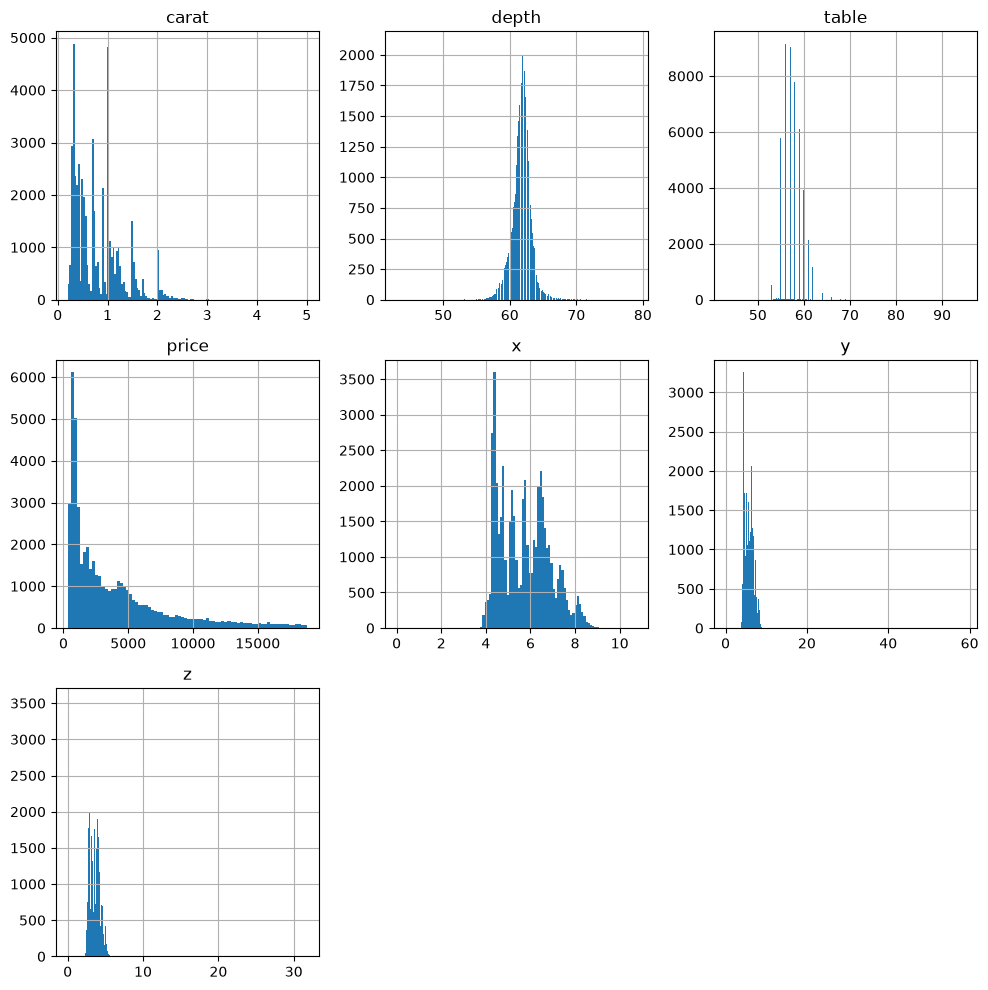

In [9]:
numerical_df.hist(bins="fd", figsize=(10, 10))
plt.tight_layout()
plt.show()

IQR = 0.64 | Q1 = 0.4 | Q3 = 1.04 


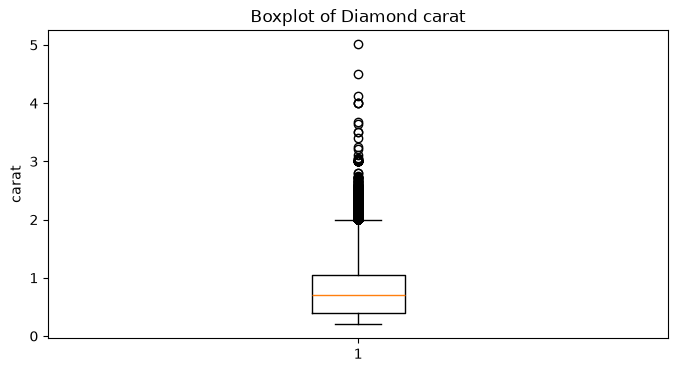

IQR = 1.5 | Q1 = 61.0 | Q3 = 62.5 


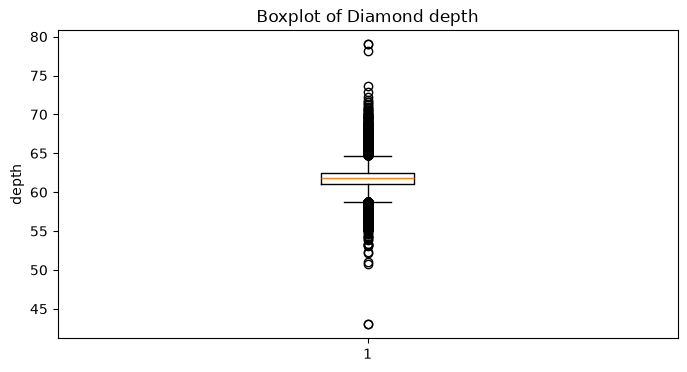

IQR = 3.0 | Q1 = 56.0 | Q3 = 59.0 


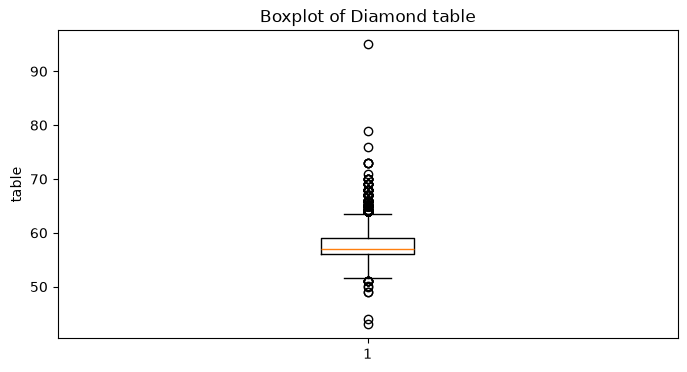

IQR = 4400.0 | Q1 = 951.0 | Q3 = 5351.0 


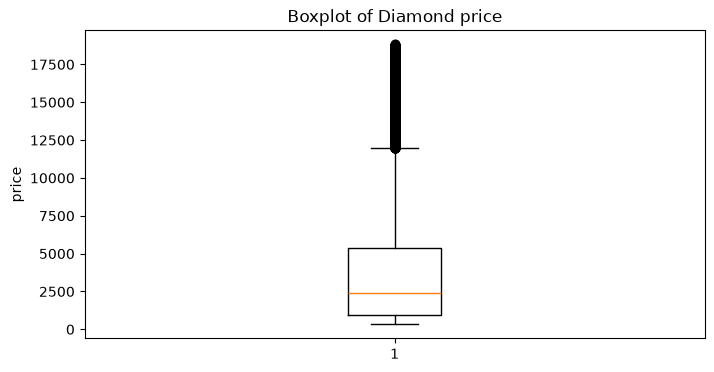

IQR = 1.83 | Q1 = 4.71 | Q3 = 6.54 


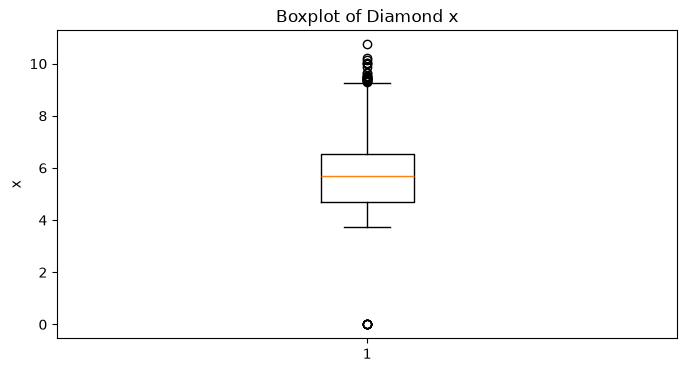

IQR = 1.8200000000000003 | Q1 = 4.72 | Q3 = 6.54 


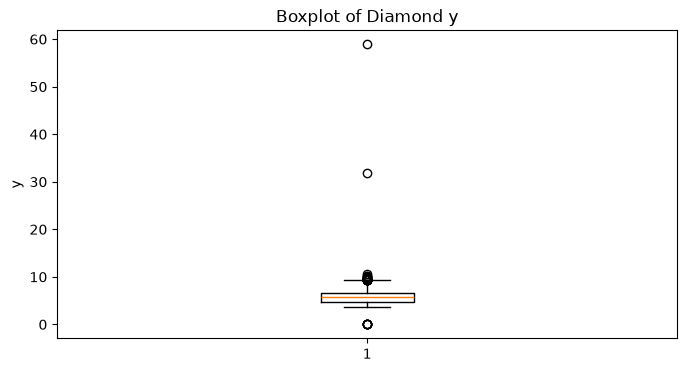

IQR = 1.13 | Q1 = 2.91 | Q3 = 4.04 


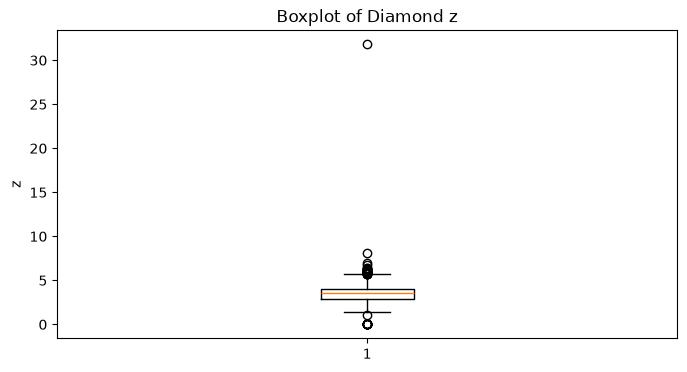

In [14]:
for col in numerical_df.columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    print(f"IQR = {IQR} | Q1 = {Q1} | Q3 = {Q3} ")

    plt.figure(figsize=(8, 4))
    plt.boxplot(df[col])
    plt.title(f"Boxplot of Diamond {col}")
    plt.ylabel(col)
    plt.show()
